# Notebook 02: Exploratory Spatial & Geochemical Data Analysis (Phase 3 & 4)
**Objectives:**
1. Quantify **spatial autocorrelation** (Global Moran's $I$ with permutation testing) across geochemical and geophysical variables.
2. Evaluate **geological host-rock enrichment** across Katangan Supergroup stratigraphic units.
3. Inspect pairwise correlations and multi-element geochemical anomalies ($\text{Cu}$, $\text{Co}$) in UTM Zone 35S (`EPSG:32735`).

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.acquisition import generate_zambia_prospectivity_benchmark, load_config
from src.data.cleaning import summarize_geochemical_outliers, validate_and_standardize_geodata
from src.features.spatial_features import compute_morans_i_knn
from src.visualization.maps import (
    plot_geochemical_and_geophysical_anomalies,
    plot_study_area_and_geology,
)

config = load_config(PROJECT_ROOT / "configs" / "config.yaml")
raw_gdf, faults_gdf = generate_zambia_prospectivity_benchmark(config)
clean_gdf, qa_report = validate_and_standardize_geodata(raw_gdf, target_crs=config["crs"]["projected_crs"])

## 1. Spatial Autocorrelation Analysis (Global Moran's $I$)
Positive spatial autocorrelation ($I > 0$, $p < 0.01$) proves that nearby samples share geological and geochemical properties—explaining why **naive random train-test splitting causes severe spatial data leakage**.

In [2]:
clean_gdf["log10_cu_ppm"] = np.log10(clean_gdf["cu_ppm"])
clean_gdf["log10_co_ppm"] = np.log10(clean_gdf["co_ppm"])

moran_rows = []
for col in ["log10_cu_ppm", "log10_co_ppm", "dist_to_fault_m", "mag_anomaly_nt", "bouguer_gravity_mgal", "elevation_m"]:
    res = compute_morans_i_knn(clean_gdf, col, k_neighbors=8)
    moran_rows.append({"variable": col, **res})

moran_df = pd.DataFrame(moran_rows)
display(moran_df)

,variable,morans_i,expected_i,perm_mean_i,perm_std_i,p_value
0,log10_cu_ppm,0.4436,-0.0004,-0.0001,0.0090,0.005
1,log10_co_ppm,0.4024,-0.0004,-0.0009,0.0091,0.005
2,dist_to_fault_m,0.9785,-0.0004,-0.0003,0.0094,0.005
3,mag_anomaly_nt,0.8817,-0.0004,0.0007,0.0086,0.005
4,bouguer_gravity_mgal,0.9124,-0.0004,0.0001,0.0097,0.005
5,elevation_m,0.8676,-0.0004,0.0002,0.0093,0.005


## 2. Study Area Overview, Geological Units, and Geochemical Anomaly Maps

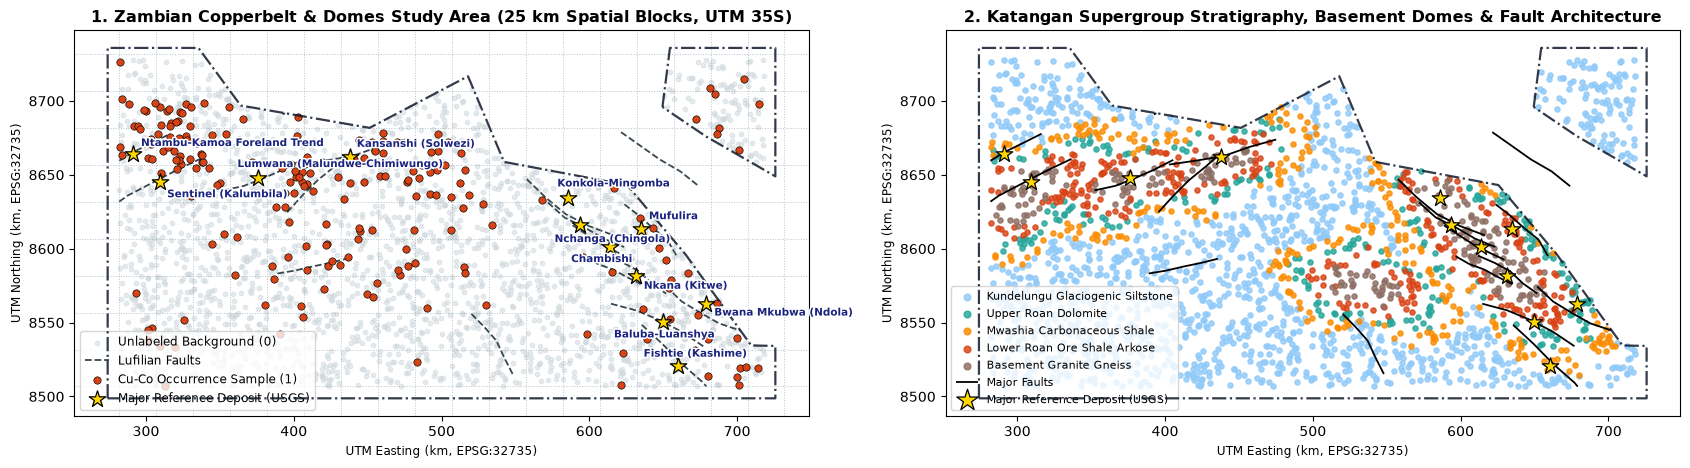

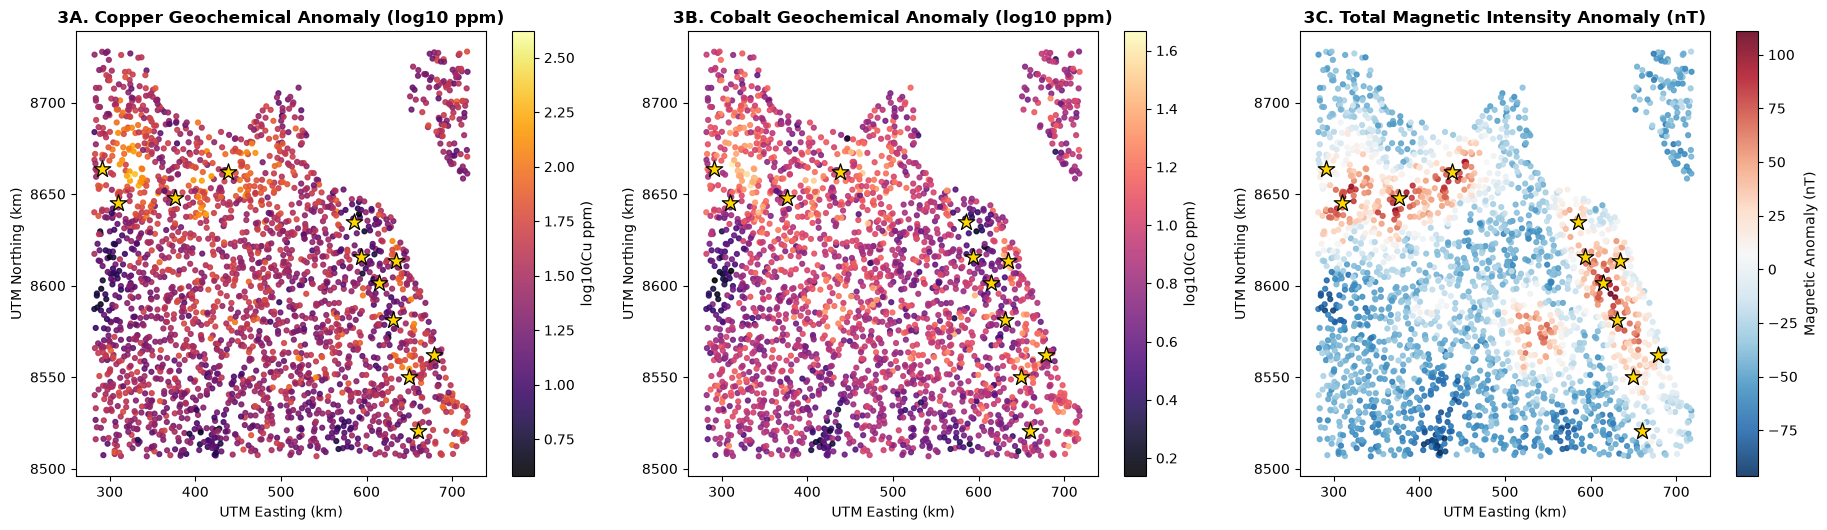

In [3]:
fig1 = plot_study_area_and_geology(
    clean_gdf,
    faults_gdf,
    save_path=PROJECT_ROOT / "data" / "processed" / "fig01_study_area_and_geology.png",
)
plt.show()

fig2 = plot_geochemical_and_geophysical_anomalies(
    clean_gdf,
    save_path=PROJECT_ROOT / "data" / "processed" / "fig02_geochem_geophysics_anomalies.png",
)
plt.show()

## 3. Spearman Rank Correlation Matrix
We use non-parametric **Spearman rank correlation** ($\rho_s$) because geological distances and trace-element assays exhibit non-linear monotonic relationships.

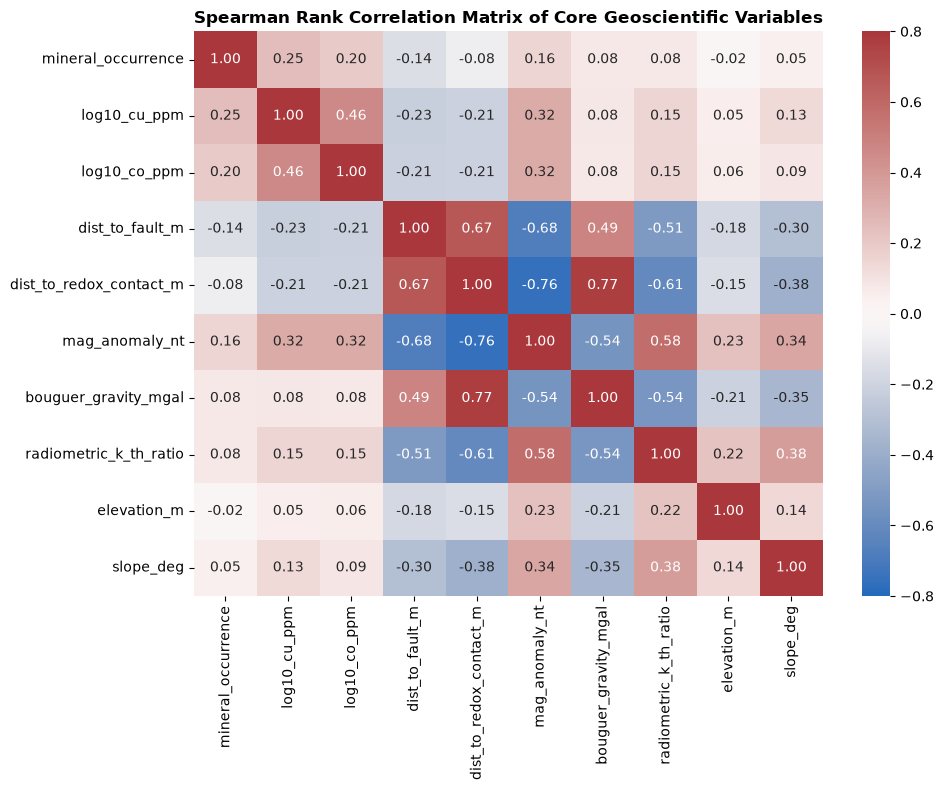

In [4]:
num_cols = [
    "mineral_occurrence",
    "log10_cu_ppm",
    "log10_co_ppm",
    "dist_to_fault_m",
    "dist_to_redox_contact_m",
    "mag_anomaly_nt",
    "bouguer_gravity_mgal",
    "radiometric_k_th_ratio",
    "elevation_m",
    "slope_deg",
]
corr = clean_gdf[num_cols].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-0.8, vmax=0.8)
plt.title("Spearman Rank Correlation Matrix of Core Geoscientific Variables", fontweight="bold")
plt.tight_layout()
plt.show()